# Notebook 1 — Preparación de Datos

## Objetivo
Construir `basin_dict = {nombre: DataFrame}` a partir de los 8 ficheros CSV
de eventos hidrológicos, aplicar el método IQR para eliminar outliers (mismo patrón
que los notebooks de ejemplo) y guardar cada cuenca como
`data/clean/basins/{nombre}-without-outliers.json`.

Los **nombres de cuenca** empleados son exactamente los especificados en
`premisa_inicial.md` (columna `nombre` de los CSV):

```python
nombre = ["BailinSabiñanigo", "CidacosYanguas", "DezaEmbidDeAriza",
          "FlamisellCabdella", "GaronaBossost", "IsuelaTrasobares",
          "IzalzuAnduña", "NelaVillarcayo", "OroncilloOron",
          "RudronValdelateja", "SanguesaOnsella", "SubialdeLarrinoa",
          "TironSanMiguelPedroso", "TruebaMedinaDePomar", "UbaguaRiezu",
          "UrriobiEspinal", "VallfarreraAlins", "ZatoyaOchagavia",
          "ZidacosGarinoiain"]
```

## Variables (nomenclatura original de los CSVs)
| Variable     | Fichero fuente                        | Descripción                       |
|---|---|---|
| `DuracionP`  | AgregadosPorCuencasDuracionP.csv      | Duración de la tormenta           |
| `DuracionQ`  | AgregadosPorCuencasDuracionQ.csv      | Duración del hidrograma           |
| `MaximoP`    | AgregadosPorCuencasMaximoP.csv        | Intensidad Máxima de Precipitación|
| `MaximoQ`    | AgregadosPorCuencasMaximoQ.csv        | Caudal Pico                       |
| `MaximoR`    | AgregadosPorCuencasMaximoR.csv        | Escorrentía máxima                |
| `Tiempos`    | AgregadosPorCuencasTiempos.csv        | Tiempos (variable objetivo)       |
| `VolumenP`   | AgregadosPorCuencasVolumenP.csv       | Volumen de Lluvia                 |
| `VolumenR`   | AgregadosPorCuencasVolumenR.csv       | Volumen Escorrentía               |

## Variables derivadas
- `MaximoR_VolumenP = MaximoR / VolumenP`
- `VolumenR_VolumenP = VolumenR / VolumenP`

## Salidas
- `data/clean/basins/{nombre}-without-outliers.json` (un fichero por cuenca)

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import warnings

warnings.filterwarnings('ignore')

RAW_PATH   = '../../data/raw/'
CLEAN_PATH = '../../data/clean/basins/'
os.makedirs(CLEAN_PATH, exist_ok=True)

print('Setup completo.')

Setup completo.


## Lista de Cuencas

In [2]:
# Nombres exactos de la premisa_inicial.md (columna 'nombre' de los CSV)
nombre = [
    "BailinSabiñanigo", "CidacosYanguas", "DezaEmbidDeAriza",
    "FlamisellCabdella", "GaronaBossost", "IsuelaTrasobares",
    "IzalzuAnduña", "NelaVillarcayo", "OroncilloOron",
    "RudronValdelateja", "SanguesaOnsella", "SubialdeLarrinoa",
    "TironSanMiguelPedroso", "TruebaMedinaDePomar", "UbaguaRiezu",
    "UrriobiEspinal", "VallfarreraAlins", "ZatoyaOchagavia",
    "ZidacosGarinoiain"
]

print(f'Cuencas en estudio: {len(nombre)}')
print(nombre)

Cuencas en estudio: 19
['BailinSabiñanigo', 'CidacosYanguas', 'DezaEmbidDeAriza', 'FlamisellCabdella', 'GaronaBossost', 'IsuelaTrasobares', 'IzalzuAnduña', 'NelaVillarcayo', 'OroncilloOron', 'RudronValdelateja', 'SanguesaOnsella', 'SubialdeLarrinoa', 'TironSanMiguelPedroso', 'TruebaMedinaDePomar', 'UbaguaRiezu', 'UrriobiEspinal', 'VallfarreraAlins', 'ZatoyaOchagavia', 'ZidacosGarinoiain']


## Lectura de Datos

In [3]:
# Ficheros de entrada (8 variables, excluye VolumenQ)
FILES = {
    'DuracionP': 'AgregadosPorCuencasDuracionP.csv',
    'DuracionQ': 'AgregadosPorCuencasDuracionQ.csv',
    'MaximoP':   'AgregadosPorCuencasMaximoP.csv',
    'MaximoQ':   'AgregadosPorCuencasMaximoQ.csv',
    'MaximoR':   'AgregadosPorCuencasMaximoR.csv',
    'Tiempos':   'AgregadosPorCuencasTiempos.csv',
    'VolumenP':  'AgregadosPorCuencasVolumenP.csv',
    'VolumenR':  'AgregadosPorCuencasVolumenR.csv',
}

# Leer en formato wide: fila = cuenca (nombre), columna = evento t0..tN
raw_wide = {}
for var, fname in FILES.items():
    df = pd.read_csv(os.path.join(RAW_PATH, fname), index_col='nombre')
    raw_wide[var] = df
    print(f'{var}: {df.shape}  (cuencas x eventos)')

n_eventos = raw_wide['Tiempos'].shape[1]
print(f'\nTotal eventos por cuenca: {n_eventos}')

# Verificar que las cuencas del CSV coinciden exactamente con las del .md
csv_names = sorted(raw_wide['Tiempos'].index.tolist())
md_names  = sorted(nombre)
assert csv_names == md_names, f'Discrepancia en nombres: {set(csv_names) ^ set(md_names)}'
print('OK: nombres del CSV coinciden con premisa_inicial.md')

DuracionP: (19, 3638)  (cuencas x eventos)
DuracionQ: (19, 3638)  (cuencas x eventos)
MaximoP: (19, 3638)  (cuencas x eventos)
MaximoQ: (19, 3638)  (cuencas x eventos)
MaximoR: (19, 3638)  (cuencas x eventos)
Tiempos: (19, 3638)  (cuencas x eventos)
VolumenP: (19, 3638)  (cuencas x eventos)
VolumenR: (19, 3638)  (cuencas x eventos)

Total eventos por cuenca: 3638
OK: nombres del CSV coinciden con premisa_inicial.md


## Construcción de basin_dict

In [4]:
# basin_dict = {nombre_cuenca: DataFrame(eventos x variables)}
# El identificador de cuenca es exactamente el nombre del .md
basin_dict = {}

for cuenca in nombre:
    frames = {}
    for var, wide_df in raw_wide.items():
        frames[var] = wide_df.loc[cuenca].values.astype(float)

    df = pd.DataFrame(frames)
    df.index.name = 'evento_id'
    df['Area_nm'] = cuenca          # nombre exacto del .md
    basin_dict[cuenca] = df

# Verificación
sample = nombre[0]
print(f'Cuencas en basin_dict: {len(basin_dict)}')
print(f'\nEjemplo ({sample}): shape={basin_dict[sample].shape}')
print(basin_dict[sample].head(3))

Cuencas en basin_dict: 19

Ejemplo (BailinSabiñanigo): shape=(3638, 9)
           DuracionP  DuracionQ  MaximoP   MaximoQ  MaximoR  Tiempos  \
evento_id                                                              
0                0.5       4.75  1127.05  0.252392  1127.05      0.5   
1               38.0      23.25  1127.05  0.203289  1127.05     38.0   
2              120.5       4.50  1127.05  0.159071  1127.05    120.5   

           VolumenP  VolumenR           Area_nm  
evento_id                                        
0            9016.4    9016.4  BailinSabiñanigo  
1           22541.0   22541.0  BailinSabiñanigo  
2            4508.2    4508.2  BailinSabiñanigo  


# Análisis Exploratorio de Datos

In [5]:
df_all = pd.concat(basin_dict.values(), ignore_index=True)
print(f'Total eventos (antes de limpieza): {len(df_all):,}')
print()
print('Estadísticas descriptivas:')
display(df_all.describe().round(2))

Total eventos (antes de limpieza): 69,122

Estadísticas descriptivas:


,DuracionP,DuracionQ,MaximoP,MaximoQ,MaximoR,Tiempos,VolumenP,VolumenR
count,30997.00,30997.00,30997.00,30997.00,30997.00,30997.00,30997.00,30997.00
mean,188.64,12.40,83371.83,7.93,45997.92,188.64,532024.87,276306.19
std,245.70,7.53,137889.66,62.80,87460.76,245.70,952939.31,490153.29
min,0.25,0.50,0.00,0.01,0.00,0.25,0.00,0.00
25%,15.25,5.75,18008.70,0.46,7203.48,15.25,76375.30,43220.88
50%,90.50,13.00,55367.18,1.30,21610.46,90.50,254733.80,136864.54
75%,275.50,18.75,110178.88,4.10,52566.16,275.50,584972.40,322168.70
max,1706.50,25.00,2595709.83,2498.61,2595709.83,1706.50,37118413.70,18689110.80


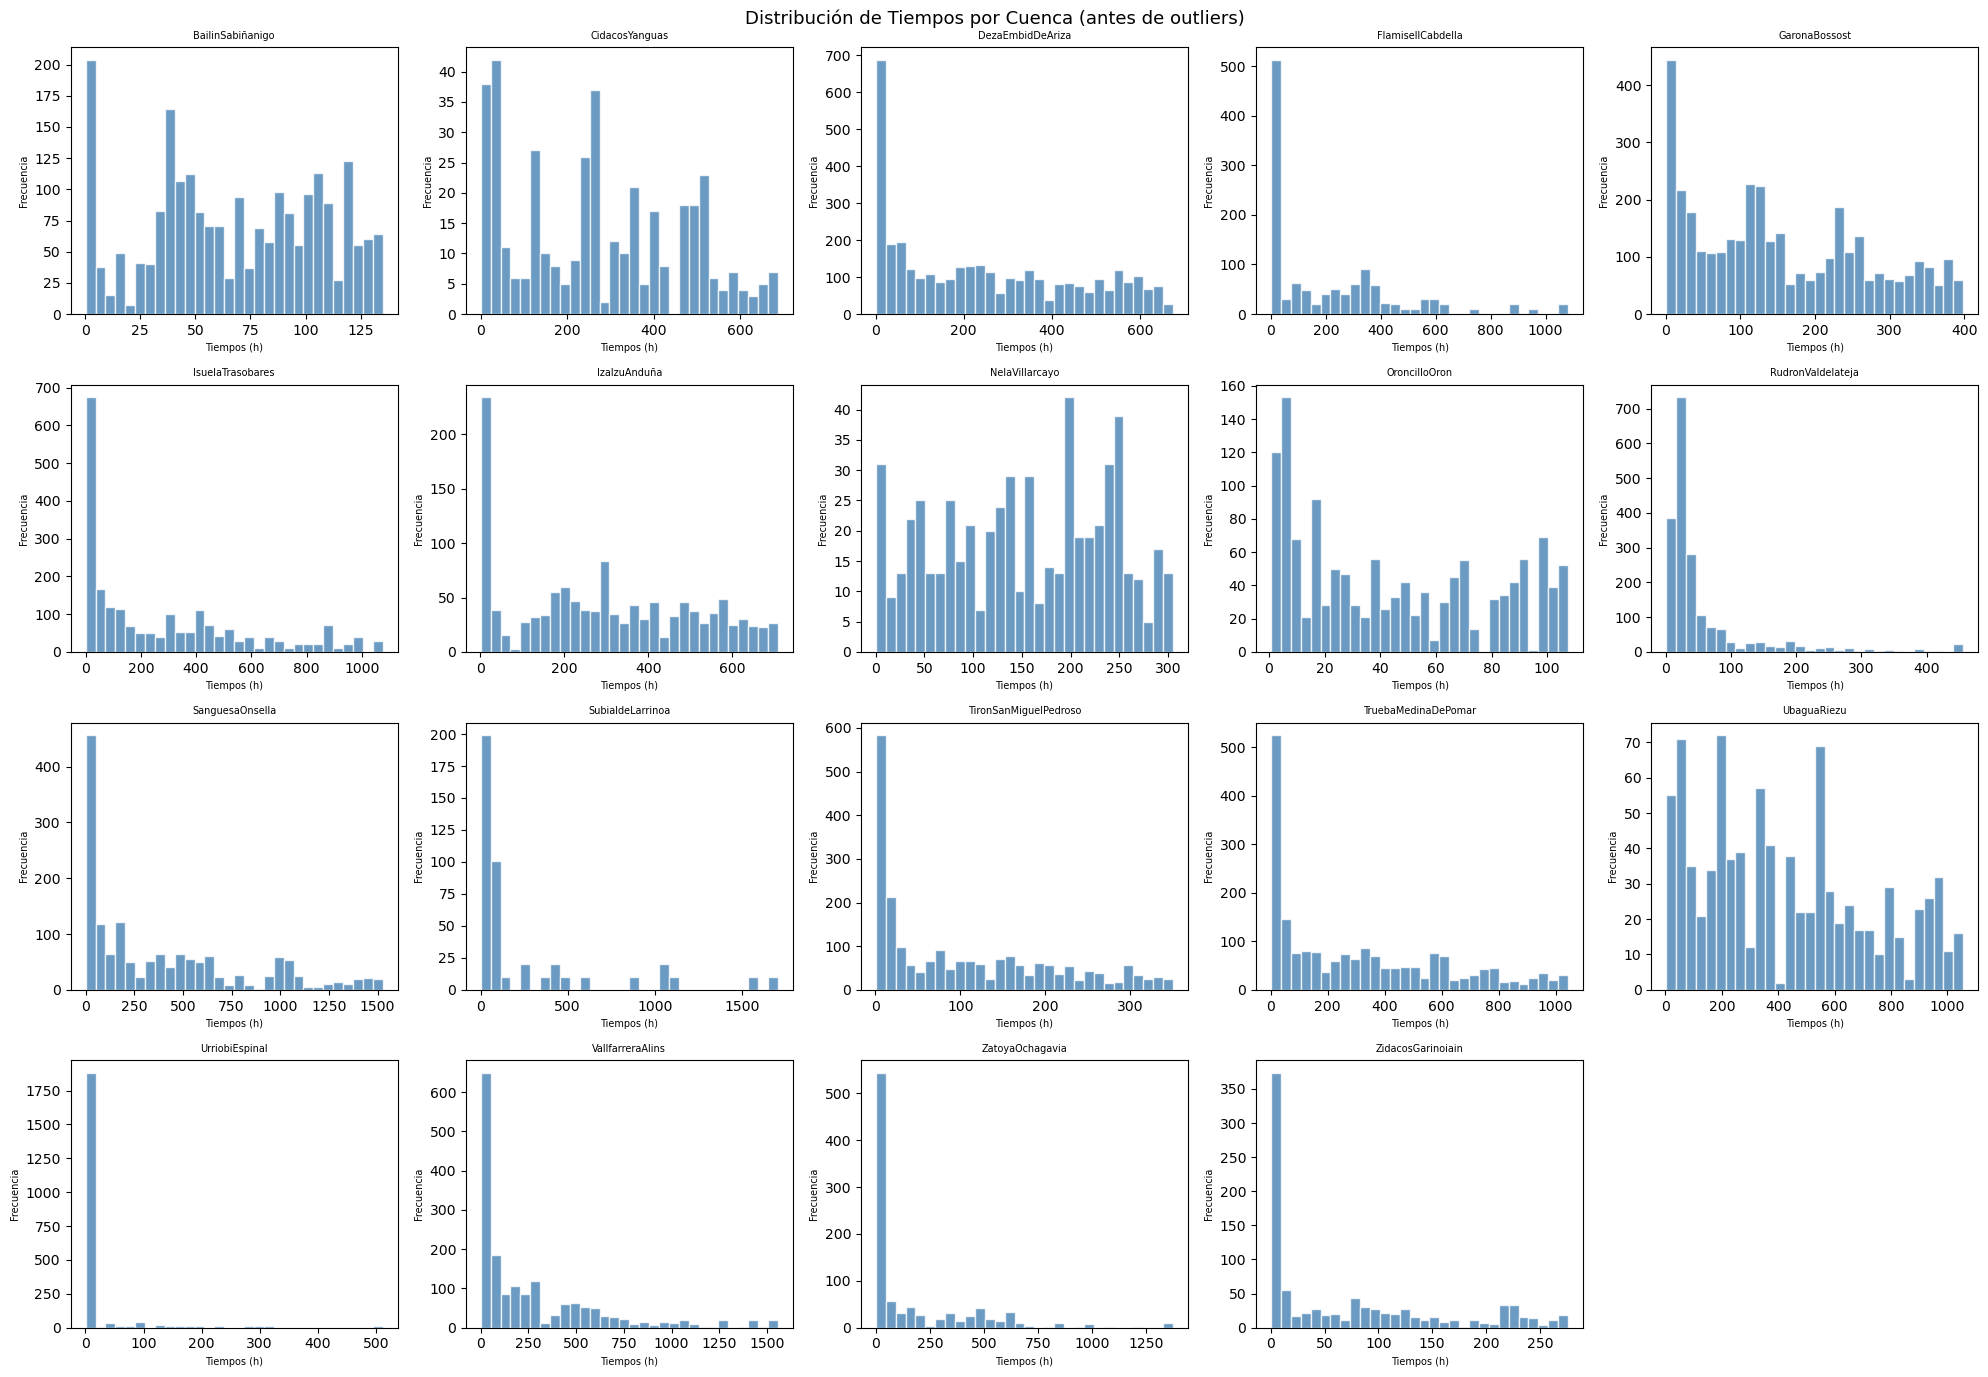

In [6]:
# Distribución de Tiempos por cuenca
fig, axes = plt.subplots(4, 5, figsize=(20, 14), sharey=False)
axes = axes.flatten()

for i, cuenca in enumerate(nombre):
    df = basin_dict[cuenca]
    axes[i].hist(df['Tiempos'].dropna(), bins=30,
                 color='steelblue', edgecolor='white', alpha=0.8)
    # Etiqueta corta para legibilidad
    axes[i].set_title(cuenca, fontsize=7)
    axes[i].set_xlabel('Tiempos (h)', fontsize=7)
    axes[i].set_ylabel('Frecuencia', fontsize=7)

for j in range(len(nombre), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Distribución de Tiempos por Cuenca (antes de outliers)', fontsize=13)
plt.tight_layout()
plt.show()

# Preprocessing
## Eliminación de Outliers (método IQR)

In [7]:
def remove_outliers_iqr(data_dict, variables=None, multiplier=1.5):
    """
    Marca como NaN los valores fuera de [Q1 - mult*IQR, Q3 + mult*IQR]
    para cada variable y cada cuenca. No elimina filas.

    Parameters
    ----------
    data_dict  : dict {nombre_cuenca: pd.DataFrame}
    variables  : list of str | None
    multiplier : float

    Returns
    -------
    data_dict      : dict (modificado in-place)
    outliers_stats : dict {cuenca: {var: n_outliers}}
    """
    outliers_stats = {}
    for cuenca, df in data_dict.items():
        outliers_stats[cuenca] = {}
        cols = variables if variables is not None else df.select_dtypes(include='number').columns.tolist()
        for col in cols:
            if col not in df.columns:
                continue
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower = Q1 - multiplier * IQR
            upper = Q3 + multiplier * IQR
            mask = (df[col] < lower) | (df[col] > upper)
            n_out = int(mask.sum())
            outliers_stats[cuenca][col] = n_out
            if n_out > 0:
                df.loc[mask, col] = np.nan
    return data_dict, outliers_stats

print('Funcion remove_outliers_iqr definida.')

Funcion remove_outliers_iqr definida.


In [8]:
VARS_TO_CLEAN = ['DuracionP', 'DuracionQ', 'MaximoP', 'MaximoQ',
                 'MaximoR', 'Tiempos', 'VolumenP', 'VolumenR']

basin_dict, outliers_stats = remove_outliers_iqr(basin_dict, VARS_TO_CLEAN, multiplier=1.5)

total_out = 0
for cuenca, stats in outliers_stats.items():
    n = sum(stats.values())
    total_out += n
    print(f'{cuenca:30s}: {n:5d} outliers marcados como NaN')

print(f'\nTotal outliers marcados: {total_out:,}')

BailinSabiñanigo              :  1162 outliers marcados como NaN
CidacosYanguas                :   176 outliers marcados como NaN
DezaEmbidDeAriza              :  1762 outliers marcados como NaN
FlamisellCabdella             :   575 outliers marcados como NaN
GaronaBossost                 :  1840 outliers marcados como NaN
IsuelaTrasobares              :  1275 outliers marcados como NaN
IzalzuAnduña                  :   520 outliers marcados como NaN
NelaVillarcayo                :   233 outliers marcados como NaN
OroncilloOron                 :   663 outliers marcados como NaN
RudronValdelateja             :  1481 outliers marcados como NaN
SanguesaOnsella               :   767 outliers marcados como NaN
SubialdeLarrinoa              :   366 outliers marcados como NaN
TironSanMiguelPedroso         :  1022 outliers marcados como NaN
TruebaMedinaDePomar           :   942 outliers marcados como NaN
UbaguaRiezu                   :   351 outliers marcados como NaN
UrriobiEspinal           

In [9]:
# Variables derivadas (ANTES del dropna)
for cuenca, df in basin_dict.items():
    df['MaximoR_VolumenP']  = df['MaximoR']  / (df['VolumenP'] + 1e-9)
    df['VolumenR_VolumenP'] = df['VolumenR']  / (df['VolumenP'] + 1e-9)

print('Variables derivadas creadas: MaximoR_VolumenP, VolumenR_VolumenP')

Variables derivadas creadas: MaximoR_VolumenP, VolumenR_VolumenP


In [10]:
# Eliminar filas con NaN (DESPUÉS de IQR y variables derivadas)
for cuenca in nombre:
    n_before = len(basin_dict[cuenca])
    basin_dict[cuenca] = basin_dict[cuenca].dropna(axis=0)
    n_after  = len(basin_dict[cuenca])
    print(f'{cuenca:30s}: {n_before:6d} -> {n_after:6d} ({n_before - n_after} eliminados)')

BailinSabiñanigo              :   3638 ->   1717 (1921 eliminados)
CidacosYanguas                :   3638 ->    296 (3342 eliminados)
DezaEmbidDeAriza              :   3638 ->   2851 (787 eliminados)
FlamisellCabdella             :   3638 ->    934 (2704 eliminados)
GaronaBossost                 :   3638 ->   2655 (983 eliminados)
IsuelaTrasobares              :   3638 ->   1468 (2170 eliminados)
IzalzuAnduña                  :   3638 ->    965 (2673 eliminados)
NelaVillarcayo                :   3638 ->    423 (3215 eliminados)
OroncilloOron                 :   3638 ->   1053 (2585 eliminados)
RudronValdelateja             :   3638 ->   1382 (2256 eliminados)
SanguesaOnsella               :   3638 ->   1216 (2422 eliminados)
SubialdeLarrinoa              :   3638 ->    270 (3368 eliminados)
TironSanMiguelPedroso         :   3638 ->   1525 (2113 eliminados)
TruebaMedinaDePomar           :   3638 ->   1411 (2227 eliminados)
UbaguaRiezu                   :   3638 ->    662 (2976 eliminado

## Resumen por Cuenca

In [11]:
summary = []
for cuenca in nombre:
    df = basin_dict[cuenca]
    summary.append({
        'Cuenca':        cuenca,
        'Eventos':       len(df),
        'Tiempos_mean':  df['Tiempos'].mean(),
        'Tiempos_std':   df['Tiempos'].std(),
        'Tiempos_min':   df['Tiempos'].min(),
        'Tiempos_max':   df['Tiempos'].max(),
    })

df_summary = pd.DataFrame(summary).set_index('Cuenca')
print(f'Total eventos despues de limpieza: {df_summary["Eventos"].sum():,}')
display(df_summary.round(2))

Total eventos despues de limpieza: 23,118


,Eventos,Tiempos_mean,Tiempos_std,Tiempos_min,Tiempos_max
Cuenca,,,,,
BailinSabiñanigo,1717,67.48,38.53,0.25,135.00
CidacosYanguas,296,245.86,192.75,0.25,675.00
DezaEmbidDeAriza,2851,245.50,208.20,0.75,667.00
FlamisellCabdella,934,200.73,199.10,0.50,732.75
GaronaBossost,2655,163.12,115.37,0.50,398.75
IsuelaTrasobares,1468,305.08,306.00,0.25,1064.25
IzalzuAnduña,965,306.72,211.16,1.25,708.00
NelaVillarcayo,423,152.81,86.23,4.50,305.00
OroncilloOron,1053,43.83,33.65,0.75,107.50


In [12]:
# Guardar cada cuenca como {nombre}-without-outliers.json
# El nombre del fichero = nombre exacto del .md
# Columnas ordenadas alfabéticamente
for cuenca, df in basin_dict.items():
    out_path = os.path.join(CLEAN_PATH, f'{cuenca}-without-outliers.json')
    df.reindex(columns=sorted(df.columns)).to_json(
        out_path, orient='records', indent=4
    )
    print(f'Guardado: {cuenca}-without-outliers.json  ({len(df)} eventos)')

print('\nFicheros guardados en:', CLEAN_PATH)

Guardado: BailinSabiñanigo-without-outliers.json  (1717 eventos)
Guardado: CidacosYanguas-without-outliers.json  (296 eventos)
Guardado: DezaEmbidDeAriza-without-outliers.json  (2851 eventos)
Guardado: FlamisellCabdella-without-outliers.json  (934 eventos)
Guardado: GaronaBossost-without-outliers.json  (2655 eventos)
Guardado: IsuelaTrasobares-without-outliers.json  (1468 eventos)
Guardado: IzalzuAnduña-without-outliers.json  (965 eventos)
Guardado: NelaVillarcayo-without-outliers.json  (423 eventos)
Guardado: OroncilloOron-without-outliers.json  (1053 eventos)
Guardado: RudronValdelateja-without-outliers.json  (1382 eventos)
Guardado: SanguesaOnsella-without-outliers.json  (1216 eventos)
Guardado: SubialdeLarrinoa-without-outliers.json  (270 eventos)
Guardado: TironSanMiguelPedroso-without-outliers.json  (1525 eventos)
Guardado: TruebaMedinaDePomar-without-outliers.json  (1411 eventos)
Guardado: UbaguaRiezu-without-outliers.json  (662 eventos)
Guardado: UrriobiEspinal-without-outliers

# Save Clean Data

In [13]:
# Verificación: recargar un fichero
sample_cuenca = 'BailinSabiñanigo'
df_check = pd.read_json(os.path.join(CLEAN_PATH, f'{sample_cuenca}-without-outliers.json'),
                        orient='records')
print(f'Verificacion {sample_cuenca}: {df_check.shape}')
print(f'Columnas: {list(df_check.columns)}')
print(df_check.head(3))

Verificacion BailinSabiñanigo: (1717, 11)
Columnas: ['Area_nm', 'DuracionP', 'DuracionQ', 'MaximoP', 'MaximoQ', 'MaximoR', 'MaximoR_VolumenP', 'Tiempos', 'VolumenP', 'VolumenR', 'VolumenR_VolumenP']
            Area_nm  DuracionP  DuracionQ  MaximoP   MaximoQ  MaximoR  \
0  BailinSabiñanigo        0.5       4.75  1127.05  0.252392  1127.05   
1  BailinSabiñanigo      120.5       4.50  1127.05  0.159071  1127.05   
2  BailinSabiñanigo       80.5       2.50  1127.05  0.306285  1127.05   

   MaximoR_VolumenP  Tiempos  VolumenP  VolumenR  VolumenR_VolumenP  
0             0.125      0.5    9016.4    9016.4                1.0  
1             0.250    120.5    4508.2    4508.2                1.0  
2             0.125     80.5    9016.4    9016.4                1.0  


## Creación de Dataset Consolidado (Long Format)

Convertir `basin_dict` a formato largo y guardar como `data/processed/events_dataset.csv`
para uso en notebooks de modelos predictivos.

In [14]:
# Crear directorio processed
PROC_PATH = '../../data/processed/'
os.makedirs(PROC_PATH, exist_ok=True)

print(f'Directorio processed: {PROC_PATH}')

Directorio processed: ../../data/processed/


In [15]:
# Mapeo: nombre completo -> nombre corto (para compatibilidad con notebooks 3-xxx)
# Añado este mapeo de igual a igual para reaprovechar los nb
NOMBRE_CORTO_MAP = {
    'BailinSabiñanigo': 'Bailin',
    'CidacosYanguas': 'Yanguas',
    'DezaEmbidDeAriza': 'Deza',
    'FlamisellCabdella': 'Flamisell',
    'GaronaBossost': 'Garona',
    'IsuelaTrasobares': 'Isuela',
    'IzalzuAnduña': 'Anduña',
    'NelaVillarcayo': 'Nela',
    'OroncilloOron': 'Oroncillo',
    'RudronValdelateja': 'Rudron',
    'SanguesaOnsella': 'Onsella',
    'SubialdeLarrinoa': 'Subialde',
    'TironSanMiguelPedroso': 'Tiron',
    'TruebaMedinaDePomar': 'Trueba',
    'UbaguaRiezu': 'Ubagua',
    'UrriobiEspinal': 'Espinal',
    'VallfarreraAlins': 'Vallfarrera',
    'ZatoyaOchagavia': 'Zatoya',
    'ZidacosGarinoiain': 'Zidacos'
}

print(f'Mapeo de nombres creado: {len(NOMBRE_CORTO_MAP)} cuencas')

Mapeo de nombres creado: 19 cuencas


In [16]:
# Convertir basin_dict a formato long (una fila por evento)
events_list = []

for cuenca_completa, df_cuenca in basin_dict.items():
    cuenca_corta = NOMBRE_CORTO_MAP.get(cuenca_completa, cuenca_completa)
    
    # Resetear índice para tener evento_id como columna
    df_temp = df_cuenca.reset_index()
    
    # Agregar columnas de identificación
    df_temp['cuenca'] = cuenca_corta
    df_temp['cuenca_larga'] = cuenca_completa
    
    events_list.append(df_temp)

# Concatenar todos los eventos
events_dataset = pd.concat(events_list, ignore_index=True)

print(f'Dataset consolidado: {events_dataset.shape}')
print(f'Total eventos: {len(events_dataset):,}')
print(f'\nColumnas: {list(events_dataset.columns)}')

Dataset consolidado: (23118, 14)
Total eventos: 23,118

Columnas: ['evento_id', 'DuracionP', 'DuracionQ', 'MaximoP', 'MaximoQ', 'MaximoR', 'Tiempos', 'VolumenP', 'VolumenR', 'Area_nm', 'MaximoR_VolumenP', 'VolumenR_VolumenP', 'cuenca', 'cuenca_larga']


In [17]:
# Renombrar columnas: PascalCase -> snake_case
events_dataset = events_dataset.rename(columns={
    'Tiempos': 'tiempos',
    'DuracionP': 'duracion_p',
    'DuracionQ': 'duracion_q',
    'MaximoP': 'maximo_p',
    'MaximoQ': 'maximo_q',
    'MaximoR': 'maximo_r',
    'VolumenP': 'volumen_p',
    'VolumenR': 'volumen_r',
    'MaximoR_VolumenP': 'ratio_r_p',
    'VolumenR_VolumenP': 'ratio_vr_vp'
})

# Agregar VolumenQ (si no existe, calcular aproximación o dejar como NaN)
if 'volumen_q' not in events_dataset.columns:
    events_dataset['volumen_q'] = events_dataset['volumen_r']  # Aproximación

# Eliminar columna Area_nm (redundante con cuenca_larga)
if 'Area_nm' in events_dataset.columns:
    events_dataset = events_dataset.drop(columns=['Area_nm'])

print('Columnas renombradas a snake_case')
print(f'\nColumnas finales: {list(events_dataset.columns)}')

Columnas renombradas a snake_case

Columnas finales: ['evento_id', 'duracion_p', 'duracion_q', 'maximo_p', 'maximo_q', 'maximo_r', 'tiempos', 'volumen_p', 'volumen_r', 'ratio_r_p', 'ratio_vr_vp', 'cuenca', 'cuenca_larga', 'volumen_q']


In [18]:
# Reordenar columnas en orden lógico
column_order = [
    'cuenca', 'cuenca_larga', 'evento_id',
    'tiempos', 'duracion_p', 'duracion_q',
    'maximo_p', 'maximo_q', 'maximo_r',
    'volumen_p', 'volumen_q', 'volumen_r',
    'ratio_r_p', 'ratio_vr_vp'
]

# Asegurarse de que todas las columnas existen
events_dataset = events_dataset[[col for col in column_order if col in events_dataset.columns]]

print('Columnas reordenadas')
display(events_dataset.head())

Columnas reordenadas


,cuenca,cuenca_larga,evento_id,tiempos,duracion_p,duracion_q,maximo_p,maximo_q,maximo_r,volumen_p,volumen_q,volumen_r,ratio_r_p,ratio_vr_vp
0,Bailin,BailinSabiñanigo,0,0.5,0.5,4.75,1127.05,0.252392,1127.05,9016.4,9016.4,9016.4,0.125,1.0
1,Bailin,BailinSabiñanigo,2,120.5,120.5,4.50,1127.05,0.159071,1127.05,4508.2,4508.2,4508.2,0.250,1.0
2,Bailin,BailinSabiñanigo,4,80.5,80.5,2.50,1127.05,0.306285,1127.05,9016.4,9016.4,9016.4,0.125,1.0
3,Bailin,BailinSabiñanigo,5,0.5,0.5,7.00,1127.05,0.306285,1127.05,9016.4,9016.4,9016.4,0.125,1.0
4,Bailin,BailinSabiñanigo,7,2.0,2.0,10.75,1127.05,0.428126,1127.05,4508.2,4508.2,4508.2,0.250,1.0


In [19]:
# Guardar como CSV
csv_path = os.path.join(PROC_PATH, 'events_dataset.csv')
events_dataset.to_csv(csv_path, index=False)

print(f'✓ Dataset consolidado guardado en: {csv_path}')
print(f'  - Forma: {events_dataset.shape}')
print(f'  - Total eventos: {len(events_dataset):,}')
print(f'  - Cuencas únicas: {events_dataset["cuenca"].nunique()}')

✓ Dataset consolidado guardado en: ../../data/processed/events_dataset.csv
  - Forma: (23118, 14)
  - Total eventos: 23,118
  - Cuencas únicas: 19


In [20]:
# Verificación: recargar el CSV
df_verify = pd.read_csv(csv_path)

print(f'Verificación CSV cargado: {df_verify.shape}')
print(f'\nPrimeras filas:')
display(df_verify.head())

print(f'\nCuencas en el dataset:')
print(sorted(df_verify['cuenca'].unique()))

Verificación CSV cargado: (23118, 14)

Primeras filas:


,cuenca,cuenca_larga,evento_id,tiempos,duracion_p,duracion_q,maximo_p,maximo_q,maximo_r,volumen_p,volumen_q,volumen_r,ratio_r_p,ratio_vr_vp
0,Bailin,BailinSabiñanigo,0,0.5,0.5,4.75,1127.05,0.252392,1127.05,9016.4,9016.4,9016.4,0.125,1.0
1,Bailin,BailinSabiñanigo,2,120.5,120.5,4.50,1127.05,0.159071,1127.05,4508.2,4508.2,4508.2,0.250,1.0
2,Bailin,BailinSabiñanigo,4,80.5,80.5,2.50,1127.05,0.306285,1127.05,9016.4,9016.4,9016.4,0.125,1.0
3,Bailin,BailinSabiñanigo,5,0.5,0.5,7.00,1127.05,0.306285,1127.05,9016.4,9016.4,9016.4,0.125,1.0
4,Bailin,BailinSabiñanigo,7,2.0,2.0,10.75,1127.05,0.428126,1127.05,4508.2,4508.2,4508.2,0.250,1.0



Cuencas en el dataset:
['Anduña', 'Bailin', 'Deza', 'Espinal', 'Flamisell', 'Garona', 'Isuela', 'Nela', 'Onsella', 'Oroncillo', 'Rudron', 'Subialde', 'Tiron', 'Trueba', 'Ubagua', 'Vallfarrera', 'Yanguas', 'Zatoya', 'Zidacos']


## Resumen

**Archivos generados:**

1. `data/clean/basins/{cuenca}-without-outliers.json` — 19 archivos JSON (uno por cuenca)
2. `data/processed/events_dataset.csv` — Dataset consolidado en formato largo

**El dataset `events_dataset.csv` está listo para ser usado por los notebooks de modelos predictivos (3-xxx).**